# **Student Placement Prediction — Statistical Analysis and Machine Learning**

**Course:** BAD702 – Statistical Machine Learning for Data Science

Name: ____________________

USN: ____________________

Semester: VII

# *Statistical Analysis and Machine-Learning-Based Prediction of Indian Student Placement Outcomes*

**Dataset:** `Indian_Student_Placement_Dataset_2025.csv`

This project analyses academic performance, skill indicators and demographic attributes to understand which factors are associated with student placement outcomes. It combines descriptive statistics, formal statistical hypothesis testing, and supervised machine-learning classification models (Logistic Regression, Decision Tree and Random Forest) to predict whether a student is placed, followed by model evaluation, comparison and interpretation.

## 1. Problem Definition

Campus placement outcomes depend on a mix of academic performance (CGPA), aptitude, technical/soft skills, and demographic/programme attributes. Understanding which of these factors are genuinely associated with placement — and by how much — can help institutions target training and counselling more effectively.

The problem addressed in this project is:

**Which academic, skill-based and demographic factors are statistically associated with student placement, and how accurately can placement be predicted from these factors?**

## 2. Objectives

1. Understand the structure and quality of the Indian Student Placement dataset.
2. Calculate descriptive statistics for the key numerical variables (CGPA, aptitude score, coding skills, etc.).
3. Study the distribution of these variables and how they differ between placed and not-placed students.
4. Test whether the differences in academic/skill variables between placed and not-placed students are statistically significant.
5. Test whether categorical attributes (gender, degree, branch) are associated with placement.
6. Build and compare supervised classification models to predict placement outcome.
7. Identify the most influential features for placement using model-based feature importance.

## 3. Research Questions

**RQ1:** What are the distribution and central tendencies of the key numerical variables (CGPA, aptitude score, coding skills, communication skills)?

**RQ2:** Do placed and not-placed students differ significantly in their mean CGPA, aptitude score and coding skills?

**RQ3:** Are categorical attributes (gender, degree, branch) statistically associated with placement outcome?

**RQ4:** Which variables correlate most strongly with placement?

**RQ5:** Can placement be predicted from academic, skill and demographic features, and which classification model performs best?

## 4. Dataset Description

The analysis uses the supplied `Indian_Student_Placement_Dataset_2025.csv` file.

| Variable | Description | Role |
|---|---|---|
| `student_id` | Unique identifier for each student | Identifier (dropped) |
| `gender` | Student gender | Categorical feature |
| `age` | Student age (years) | Numerical feature |
| `degree` | Degree programme (BE, BTech, BCA, BSc) | Categorical feature |
| `branch` | Branch/specialisation | Categorical feature |
| `cgpa` | Cumulative GPA | Numerical feature |
| `backlogs` | Number of pending backlogs | Numerical feature |
| `internships` | Number of internships completed | Numerical feature |
| `certifications` | Number of certifications earned | Numerical feature |
| `coding_skills` | Self/assessed coding skill score (1–10) | Numerical feature |
| `communication_skills` | Communication skill score (1–10) | Numerical feature |
| `aptitude_score` | Aptitude test score (0–100) | Numerical feature |
| `projects` | Number of projects completed | Numerical feature |
| `placed` | Placement outcome (0 = Not Placed, 1 = Placed) | **Target variable** |
| `company_type` | Type of company that placed the student | Post-outcome field (dropped — leakage) |
| `package_lpa` | Offered package in LPA | Post-outcome field (dropped — leakage) |

`company_type` and `package_lpa` are only meaningful **after** a student is placed, so they are excluded from modelling to avoid target leakage (Section 8).

## 5. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import ttest_ind, chi2_contingency, f_oneway, pointbiserialr

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_style("whitegrid")
pd.set_option("display.width", 120)

## 6. Load the Dataset

In [2]:
FILE_PATH = "Indian_Student_Placement_Dataset_2025.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (12000, 16)


,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,NaN,0.0
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,NaN,0.0
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,NaN,0.0
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,NaN,0.0
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,NaN,0.0


## 7. Initial Dataset Inspection

### Initial Data Inspection

This section checks the dataset's structure, data types, missing values, and duplicate entries to prepare for cleaning.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['student_id', 'gender', 'age', 'degree', 'branch', 'cgpa', 'backlogs', 'internships', 'certifications', 'coding_skills', 'communication_skills', 'aptitude_score', 'projects', 'placed', 'company_type', 'package_lpa']

Data types:


,Data Type
student_id,int64
gender,str
age,int64
degree,str
branch,str
cgpa,float64
backlogs,int64
internships,int64
certifications,int64
coding_skills,int64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            12000 non-null  int64  
 1   gender                12000 non-null  str    
 2   age                   12000 non-null  int64  
 3   degree                12000 non-null  str    
 4   branch                12000 non-null  str    
 5   cgpa                  12000 non-null  float64
 6   backlogs              12000 non-null  int64  
 7   internships           12000 non-null  int64  
 8   certifications        12000 non-null  int64  
 9   coding_skills         12000 non-null  int64  
 10  communication_skills  12000 non-null  int64  
 11  aptitude_score        12000 non-null  int64  
 12  projects              12000 non-null  int64  
 13  placed                12000 non-null  int64  
 14  company_type          3652 non-null   str    
 15  package_

,Missing Values
student_id,0
gender,0
age,0
degree,0
branch,0
cgpa,0
backlogs,0
internships,0
certifications,0
coding_skills,0



Duplicate rows: 0


### Inspection Results

The dataset contains **12,000 rows** and **16 columns**, with no duplicate rows. `company_type` has **8,348 missing values (69.6%)** — it is only populated when a student is placed, which is expected since a student who is not placed has no company. All other columns are fully populated. `student_id` is a unique identifier with no predictive value.

## 8. Data Preprocessing

The preprocessing steps are intentionally conservative and are guided by avoiding **target leakage**:

- Drop `student_id` — a unique identifier with no predictive value.
- Drop `company_type` — only exists **after** placement; it is a consequence of the outcome, not a predictor of it.
- Drop `package_lpa` — the offered package is **0 only when a student is not placed**, and positive only when they are placed. Using it as a feature would let the model see the answer directly.
- Confirm remaining numeric columns have sensible ranges.

In [4]:
# Work on a copy
data = df.copy()

# Drop identifier and post-outcome (leakage) columns
data = data.drop(columns=["student_id", "company_type", "package_lpa"])

print("Shape after dropping leakage/identifier columns:", data.shape)
display(data.head())

Shape after dropping leakage/identifier columns: (12000, 13)


,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed
0,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0
1,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0
2,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0
3,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0
4,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0


### Preprocessing Results

The cleaned working dataset `data` has **12,000 rows and 13 columns**: 9 numerical features (`age`, `cgpa`, `backlogs`, `internships`, `certifications`, `coding_skills`, `communication_skills`, `aptitude_score`, `projects`), 3 categorical features (`gender`, `degree`, `branch`) and the target `placed`.

## 9. Data Quality Verification

### Data Quality Verification

Checks for remaining missing values, duplicates, and verifies that numerical ranges and categorical levels are sensible.

In [5]:
print("Missing values after preprocessing:")
display(data.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows after preprocessing:", data.duplicated().sum())

numeric_cols = ["age", "cgpa", "backlogs", "internships", "certifications",
                "coding_skills", "communication_skills", "aptitude_score", "projects"]

print("\nNumeric ranges:")
display(data[numeric_cols].agg(["min", "max"]).T)

print("\nCategorical levels:")
for col in ["gender", "degree", "branch"]:
    print(f"{col}: {sorted(data[col].unique())}")

print("\nTarget distribution:")
display(data["placed"].value_counts().to_frame("Count"))

Missing values after preprocessing:


,Missing Values
gender,0
age,0
degree,0
branch,0
cgpa,0
backlogs,0
internships,0
certifications,0
coding_skills,0
communication_skills,0



Duplicate rows after preprocessing: 0

Numeric ranges:


,min,max
age,20.0,24.0
cgpa,5.5,9.8
backlogs,0.0,3.0
internships,0.0,3.0
certifications,0.0,5.0
coding_skills,1.0,10.0
communication_skills,1.0,10.0
aptitude_score,40.0,99.0
projects,0.0,5.0



Categorical levels:
gender: ['Female', 'Male']
degree: ['BCA', 'BE', 'BSc', 'BTech']
branch: ['AI', 'CS', 'DS', 'Electrical', 'IT', 'Mechanical']

Target distribution:


,Count
placed,
0,8348
1,3652


### Quality Verification Results

1. **Missing Values & Duplicates:** No missing values or duplicate rows remain in the cleaned dataset.
2. **Numeric Ranges:** All numeric columns fall within plausible bounds (e.g. `cgpa` 5.5–9.8, `aptitude_score` 40–99, `coding_skills`/`communication_skills` 1–10).
3. **Categorical Levels:** `gender` has 2 levels, `degree` has 4 levels (BCA, BE, BSc, BTech), `branch` has 6 levels.
4. **Target Distribution:** **30.4% of students are placed (3,652)** and **69.6% are not placed (8,348)** — a moderate class imbalance that is addressed later using `class_weight="balanced"` and by reporting precision/recall/F1 rather than accuracy alone.

## 10. Descriptive Statistics

### Descriptive Statistics for Key Numerical Variables

This section calculates central tendency, spread and shape statistics for the numerical variables to understand their distributions (RQ1).

In [6]:
descriptive = data[numeric_cols].describe().T
descriptive["skew"] = data[numeric_cols].skew()
descriptive["kurtosis"] = data[numeric_cols].kurt()
descriptive["IQR"] = descriptive["75%"] - descriptive["25%"]

display(descriptive.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,IQR
age,12000.0,21.988,1.422,20.0,21.00,22.000,23.00,24.0,0.014,-1.317,2.00
cgpa,12000.0,7.645,1.243,5.5,6.56,7.645,8.72,9.8,0.010,-1.206,2.16
backlogs,12000.0,1.492,1.118,0.0,0.00,1.000,2.00,3.0,0.011,-1.361,2.00
internships,12000.0,1.501,1.124,0.0,0.00,1.000,3.00,3.0,0.003,-1.373,3.00
certifications,12000.0,2.509,1.709,0.0,1.00,3.000,4.00,5.0,-0.003,-1.274,3.00
coding_skills,12000.0,5.495,2.890,1.0,3.00,5.000,8.00,10.0,0.003,-1.235,5.00
communication_skills,12000.0,5.501,2.888,1.0,3.00,6.000,8.00,10.0,-0.010,-1.235,5.00
aptitude_score,12000.0,69.328,17.338,40.0,54.00,69.000,84.00,99.0,0.008,-1.206,30.00
projects,12000.0,2.505,1.699,0.0,1.00,3.000,4.00,5.0,-0.010,-1.259,3.00


### Descriptive Statistics Interpretation

- **CGPA:** mean **7.65**, std **1.24**, range 5.5–9.8, skew ≈ 0.01 → essentially symmetric.
- **Aptitude score:** mean **69.33**, std **17.34**, range 40–99, skew ≈ 0.01 → symmetric.
- **Coding skills:** mean **5.50**, std **2.89**, range 1–10, skew ≈ 0.003 → symmetric.
- **Communication skills:** mean **5.50**, std **2.89**, similar shape to coding skills.
- All numerical variables have skewness and kurtosis close to zero, indicating **roughly symmetric, uniform-like distributions** rather than the strongly right-skewed shape typical of real-world placement data — a point revisited in the Limitations section.

## 11. Distribution of Key Numerical Variables

### Distribution Visualisation

Visualises `cgpa`, `aptitude_score` and `coding_skills` using histograms and boxplots to check shape, central tendency, spread and outliers (RQ1).

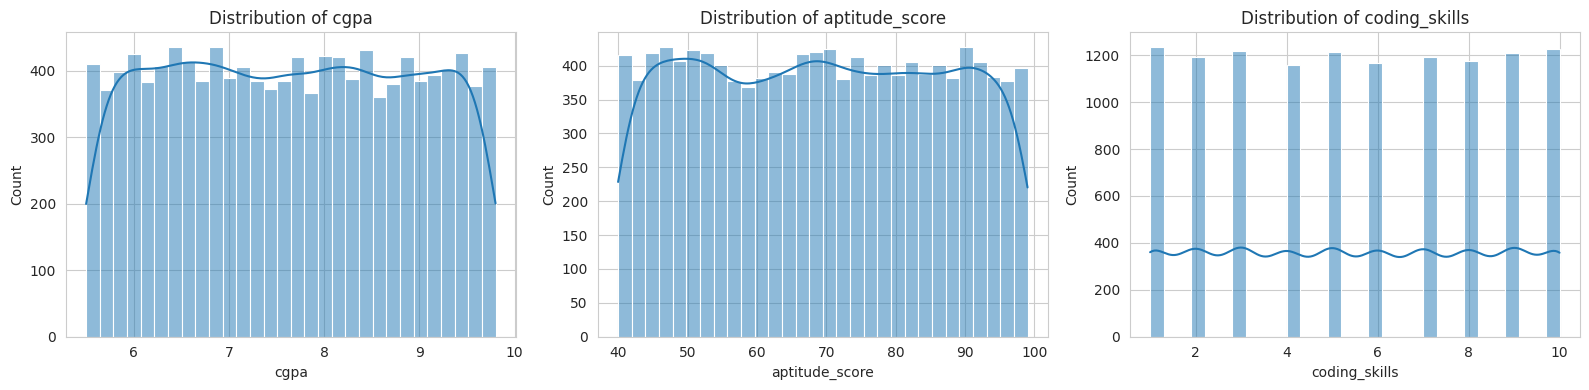

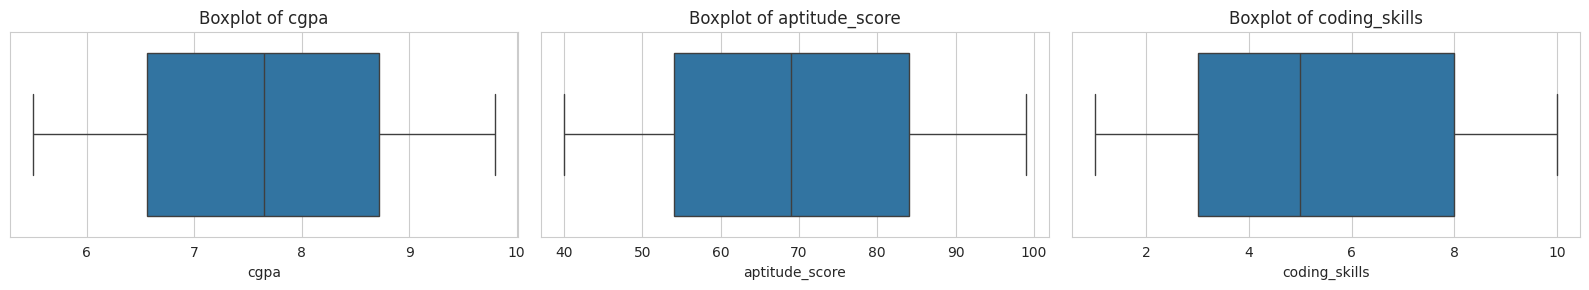

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["cgpa", "aptitude_score", "coding_skills"]):
    sns.histplot(data[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 3))
for ax, col in zip(axes, ["cgpa", "aptitude_score", "coding_skills"]):
    sns.boxplot(x=data[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

### Distribution Observations

The histograms show approximately symmetric, near-uniform distributions for `cgpa`, `aptitude_score` and `coding_skills`, consistent with the low skewness values reported above. The boxplots show **no extreme outliers** for any of the three variables — all values lie within the whiskers, so no outlier trimming was required for these features (unlike a real-world dataset, which would typically show more skew and outliers).

## 12. Target Variable Distribution

### Placement Outcome Distribution

Examines the balance of the target variable `placed`, which affects both modelling strategy and evaluation-metric choice.

,Count,Percentage
Not Placed (0),8348,69.57
Placed (1),3652,30.43


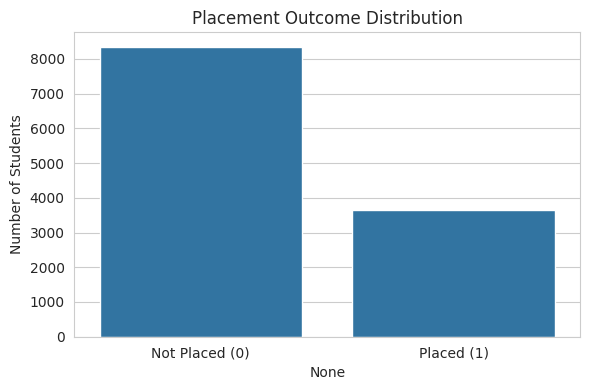

In [8]:
placed_counts = data["placed"].value_counts().sort_index()
placed_pct = (data["placed"].value_counts(normalize=True) * 100).sort_index()

summary_target = pd.DataFrame({"Count": placed_counts, "Percentage": placed_pct.round(2)})
summary_target.index = ["Not Placed (0)", "Placed (1)"]
display(summary_target)

plt.figure(figsize=(6, 4))
sns.barplot(x=summary_target.index, y=summary_target["Count"])
plt.title("Placement Outcome Distribution")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### Target Distribution Observations

The dataset is moderately imbalanced: **69.6% Not Placed** vs **30.4% Placed**. This means a trivial "always predict Not Placed" classifier would already reach ~69.6% accuracy, so **accuracy alone is not a sufficient metric** — precision, recall, F1 and ROC-AUC are also reported for all models.

## 13. Categorical Variable Analysis

### Placement Rate by Gender, Degree and Branch

Explores whether placement rate varies visibly across `gender`, `degree` and `branch` before formally testing association with a chi-square test (RQ3).

Placement rate by gender:


,count,placement_rate
gender,,
Female,5992,0.306575
Male,6008,0.302097


Placement rate by degree:


,count,placement_rate
degree,,
BSc,2977,0.317770
BE,2981,0.317008
BTech,2971,0.297206
BCA,3071,0.285900


Placement rate by branch:


,count,placement_rate
branch,,
DS,1991,0.321447
Mechanical,2107,0.310869
AI,2016,0.302579
Electrical,1981,0.299849
CS,1950,0.297949
IT,1955,0.292583


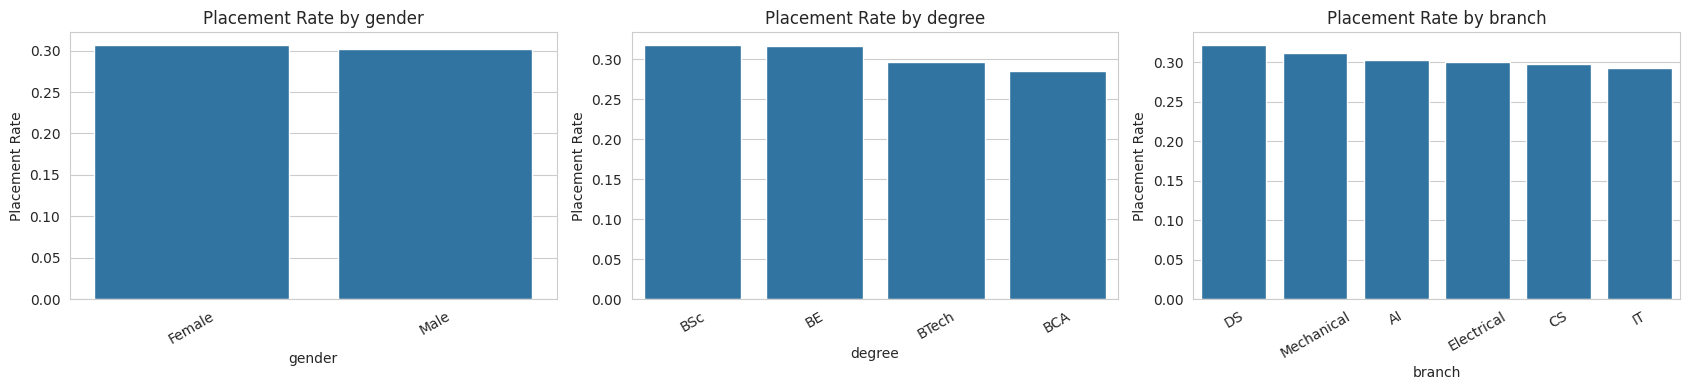

In [9]:
for col in ["gender", "degree", "branch"]:
    rate = data.groupby(col)["placed"].agg(["count", "mean"])
    rate = rate.rename(columns={"mean": "placement_rate"}).sort_values("placement_rate", ascending=False)
    print(f"Placement rate by {col}:")
    display(rate)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["gender", "degree", "branch"]):
    rate = data.groupby(col)["placed"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Placement Rate by {col}")
    ax.set_ylabel("Placement Rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Categorical Analysis Observations

Placement rates are **very similar across gender categories** (~30% for both). Across `degree` and `branch`, placement rates also cluster close to the overall 30.4% rate, with only small differences between groups. This visual similarity suggests these categorical attributes may have little or no real association with placement — formally tested next with chi-square tests.

## 14. Correlation Analysis

### Correlation with Placement

Computes the point-biserial correlation between each numerical variable and the binary target `placed`, and a Pearson correlation heatmap among the numerical variables, to identify the strongest linear associations (RQ4).

,correlation,p_value
coding_skills,0.4626,0.0000
aptitude_score,0.3901,0.0000
cgpa,0.2652,0.0000
internships,0.0166,0.0697
certifications,0.0068,0.4566
backlogs,-0.0007,0.9397
communication_skills,-0.0055,0.5450
age,-0.0067,0.4649
projects,-0.0225,0.0136


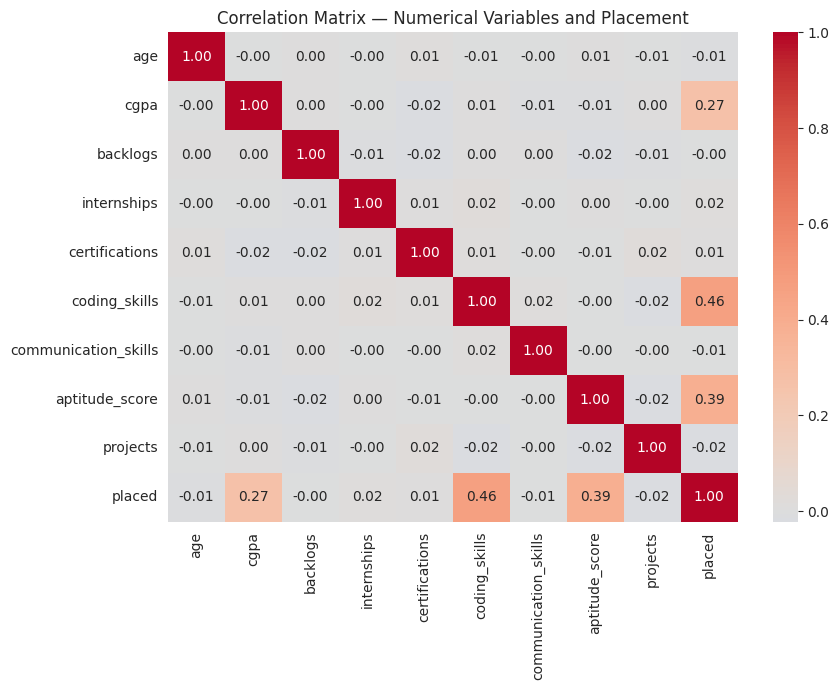

In [10]:
corr_with_target = {}
for col in numeric_cols:
    r, p = pointbiserialr(data["placed"], data[col])
    corr_with_target[col] = {"correlation": r, "p_value": p}

corr_target_df = pd.DataFrame(corr_with_target).T.sort_values("correlation", ascending=False)
display(corr_target_df.round(4))

plt.figure(figsize=(9, 7))
sns.heatmap(data[numeric_cols + ["placed"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix — Numerical Variables and Placement")
plt.tight_layout()
plt.show()

### Correlation Analysis Observations

`coding_skills` has the strongest association with placement (**r ≈ 0.463**), followed by `aptitude_score` (**r ≈ 0.390**) and `cgpa` (**r ≈ 0.265**), all with p-values effectively 0. All other numerical variables (`communication_skills`, `internships`, `certifications`, `projects`, `backlogs`, `age`) show **negligible correlation with placement (|r| < 0.03)**. This already points to `coding_skills`, `aptitude_score` and `cgpa` as the dominant drivers of placement in this dataset.

# 15. Statistical Analysis

All hypothesis tests use a significance level of:

**α = 0.05**

Decision rule:

- If **p < 0.05**, reject H₀.
- If **p ≥ 0.05**, fail to reject H₀.

Because the sample is large (n = 12,000), statistical significance is interpreted together with **effect size** (Cohen's *d* for t-tests, Cramér's V for chi-square tests, η² for ANOVA), since large samples can make even tiny, practically unimportant differences "statistically significant".

## 15.1 Confidence Interval for Mean CGPA

**H₀/H₁ are not required for a confidence interval.**

We estimate a 95% confidence interval for the population mean CGPA using the t-distribution.

In [11]:
cgpa = data["cgpa"]
n = len(cgpa)
mean_cgpa = cgpa.mean()
sem_cgpa = stats.sem(cgpa)

ci_low, ci_high = stats.t.interval(confidence=0.95, df=n - 1, loc=mean_cgpa, scale=sem_cgpa)

print(f"Mean CGPA = {mean_cgpa:.4f}")
print(f"95% Confidence Interval = ({ci_low:.4f}, {ci_high:.4f})")

Mean CGPA = 7.6453
95% Confidence Interval = (7.6231, 7.6676)


### Confidence Interval Interpretation

The mean CGPA is **7.645**, with a 95% confidence interval of approximately **(7.623, 7.668)**. We are 95% confident the true population mean CGPA lies in this narrow range — the interval is tight because of the large sample size.

## 15.2 Hypothesis Test — CGPA: Placed vs Not Placed

**RQ2:** Do placed and not-placed students differ significantly in mean CGPA?

**H₀:** Mean CGPA is equal for placed and not-placed students.

**H₁:** Mean CGPA differs between placed and not-placed students.

**Test:** Welch's independent-samples t-test (does not assume equal variances).

In [12]:
def welch_ttest_with_effect(data, col, group_col="placed"):
    g1 = data.loc[data[group_col] == 1, col]
    g0 = data.loc[data[group_col] == 0, col]
    t_stat, p_val = ttest_ind(g1, g0, equal_var=False)
    pooled_std = np.sqrt(((len(g1) - 1) * g1.std()**2 + (len(g0) - 1) * g0.std()**2) / (len(g1) + len(g0) - 2))
    cohens_d = (g1.mean() - g0.mean()) / pooled_std
    return {
        "mean_placed": g1.mean(), "mean_not_placed": g0.mean(),
        "t_statistic": t_stat, "p_value": p_val, "cohens_d": cohens_d
    }

cgpa_result = welch_ttest_with_effect(data, "cgpa")
for k, v in cgpa_result.items():
    print(f"{k}: {v:.4f}")

if cgpa_result["p_value"] < 0.05:
    print("\nDecision: Reject H0. CGPA differs significantly between placed and not-placed students.")
else:
    print("\nDecision: Fail to reject H0.")

mean_placed: 8.1438
mean_not_placed: 7.4272
t_statistic: 33.6417
p_value: 0.0000
cohens_d: 0.5976

Decision: Reject H0. CGPA differs significantly between placed and not-placed students.


### CGPA t-test Result

Placed students have a mean CGPA of **8.14** vs **7.43** for not-placed students (**t = 33.64, p < 0.001**). H₀ is rejected. **Cohen's d ≈ 0.60**, a **medium-to-large** effect — placed students have a meaningfully higher CGPA on average.

## 15.3 Hypothesis Test — Aptitude Score and Coding Skills: Placed vs Not Placed

**H₀:** Mean aptitude score (and separately, coding skills) is equal for placed and not-placed students.

**H₁:** The means differ between the two groups.

**Test:** Welch's independent-samples t-test.

In [13]:
aptitude_result = welch_ttest_with_effect(data, "aptitude_score")
coding_result = welch_ttest_with_effect(data, "coding_skills")

for name, res in [("aptitude_score", aptitude_result), ("coding_skills", coding_result)]:
    print(f"--- {name} ---")
    for k, v in res.items():
        print(f"{k}: {v:.4f}")
    print()

--- aptitude_score ---
mean_placed: 79.5526
mean_not_placed: 64.8548
t_statistic: 54.4338
p_value: 0.0000
cohens_d: 0.9206

--- coding_skills ---
mean_placed: 7.5164
mean_not_placed: 4.6112
t_statistic: 68.6002
p_value: 0.0000
cohens_d: 1.1340



### Aptitude Score & Coding Skills t-test Results

- **Aptitude score:** placed mean **79.55** vs not-placed mean **64.86** (**t = 54.43, p < 0.001, Cohen's d ≈ 0.92** — a **large** effect).
- **Coding skills:** placed mean **7.52** vs not-placed mean **4.61** (**t = 68.60, p < 0.001, Cohen's d ≈ 1.13** — a **very large** effect, the strongest of all variables tested).

Both differences are statistically significant with large practical effect sizes, confirming these two variables are strong discriminators of placement.

## 15.4 Hypothesis Tests — Remaining Numerical Variables

The same Welch's t-test and Cohen's *d* are applied to the remaining numerical variables (`communication_skills`, `internships`, `certifications`, `projects`, `backlogs`, `age`) to check whether any of them also differ meaningfully by placement.

In [14]:
remaining_cols = ["communication_skills", "internships", "certifications", "projects", "backlogs", "age"]
rows = []
for col in remaining_cols:
    res = welch_ttest_with_effect(data, col)
    rows.append({"variable": col, **res})

remaining_summary = pd.DataFrame(rows).set_index("variable").round(4)
display(remaining_summary)

,mean_placed,mean_not_placed,t_statistic,p_value,cohens_d
variable,,,,,
communication_skills,5.4765,5.5111,-0.6020,0.5472,-0.0120
internships,1.5293,1.4889,1.8073,0.0708,0.0360
certifications,2.5266,2.5013,0.7460,0.4557,0.0148
projects,2.4469,2.5301,-2.4646,0.0137,-0.0490
backlogs,1.4904,1.4921,-0.0755,0.9398,-0.0015
age,21.9740,21.9946,-0.7285,0.4663,-0.0145


### Remaining Variables — Observations

For all six remaining variables, **Cohen's d is below 0.05 in magnitude** (negligible effect size) even where the p-value is technically below 0.05 (e.g. `projects`, p ≈ 0.014). This is a textbook example of **statistical significance without practical significance**, driven by the large sample size (n = 12,000). None of these variables meaningfully distinguishes placed from not-placed students.

## 15.5 Hypothesis Tests — Categorical Attributes vs Placement

**RQ3:** Are `gender`, `degree` and `branch` statistically associated with placement?

**H₀:** The categorical attribute is independent of placement.

**H₁:** The categorical attribute is associated with placement.

**Test:** Pearson's chi-square test of independence, with **Cramér's V** as the effect size.

In [15]:
def chi_square_with_effect(data, col, target="placed"):
    ct = pd.crosstab(data[col], data[target])
    chi2, p, dof, expected = chi2_contingency(ct)
    n_total = ct.sum().sum()
    r, k = ct.shape
    cramers_v = np.sqrt(chi2 / (n_total * (min(r, k) - 1)))
    return chi2, p, dof, cramers_v, ct

for col in ["gender", "degree", "branch"]:
    chi2, p, dof, cramers_v, ct = chi_square_with_effect(data, col)
    print(f"--- {col} vs placed ---")
    print(f"Chi-square = {chi2:.4f}, dof = {dof}, p-value = {p:.4f}, Cramer's V = {cramers_v:.4f}")
    if p < 0.05:
        print("Decision: Reject H0 (statistically significant association).")
    else:
        print("Decision: Fail to reject H0 (no significant association).")
    print()

--- gender vs placed ---
Chi-square = 0.2634, dof = 1, p-value = 0.6078, Cramer's V = 0.0047
Decision: Fail to reject H0 (no significant association).

--- degree vs placed ---
Chi-square = 10.4417, dof = 3, p-value = 0.0152, Cramer's V = 0.0295
Decision: Reject H0 (statistically significant association).

--- branch vs placed ---
Chi-square = 5.0470, dof = 5, p-value = 0.4102, Cramer's V = 0.0205
Decision: Fail to reject H0 (no significant association).



### Chi-Square Test Results

- **Gender vs placed:** χ² = 0.26, p ≈ 0.608 → **fail to reject H₀**; no association (Cramér's V ≈ 0.005, negligible).
- **Degree vs placed:** χ² = 10.44, p ≈ 0.015 → **reject H₀** at α = 0.05, but Cramér's V ≈ 0.029 is **negligible in practical terms**.
- **Branch vs placed:** χ² = 5.05, p ≈ 0.410 → **fail to reject H₀**; no association (Cramér's V ≈ 0.021, negligible).

Overall, none of the categorical demographic/programme attributes have a practically meaningful association with placement — consistent with the similar placement rates observed in Section 13.

## 15.6 Hypothesis Test — CGPA Across Branches

**RQ1/RQ3:** Does mean CGPA differ significantly across branches (independent of placement)?

**H₀:** Mean CGPA is equal across all branches.

**H₁:** At least one branch has a different mean CGPA.

**Test:** One-way ANOVA.

In [16]:
branch_groups = [data.loc[data["branch"] == b, "cgpa"] for b in data["branch"].unique()]
branch_f, branch_p = f_oneway(*branch_groups)

print(f"F-statistic = {branch_f:.4f}")
print(f"p-value = {branch_p:.4f}")

if branch_p < 0.05:
    print("Decision: Reject H0. Mean CGPA differs significantly across branches.")
else:
    print("Decision: Fail to reject H0. No significant difference in mean CGPA across branches.")

F-statistic = 1.2011
p-value = 0.3058
Decision: Fail to reject H0. No significant difference in mean CGPA across branches.


### CGPA-by-Branch ANOVA Result

**F = 1.20, p ≈ 0.306** → fail to reject H₀. Mean CGPA does **not** differ significantly across branches, so no Tukey HSD post-hoc test is needed here (unlike the AQI reference project, where the seasonal/state ANOVA was significant and warranted post-hoc testing).

## 15.7 Statistical Analysis Summary

| Test | Variable(s) | Result | Effect Size | Practical Significance |
|---|---|---|---|---|
| 95% CI | Mean CGPA | (7.623, 7.668) | — | Narrow interval due to large *n* |
| Welch t-test | CGPA vs placed | p < 0.001 | d ≈ 0.60 | Medium–large |
| Welch t-test | Aptitude score vs placed | p < 0.001 | d ≈ 0.92 | Large |
| Welch t-test | Coding skills vs placed | p < 0.001 | d ≈ 1.13 | Very large (strongest) |
| Welch t-test | Other numeric vars vs placed | mixed p-values | |d| < 0.05 | Negligible |
| Chi-square | Gender vs placed | p ≈ 0.608 | V ≈ 0.005 | None |
| Chi-square | Degree vs placed | p ≈ 0.015 | V ≈ 0.029 | Negligible |
| Chi-square | Branch vs placed | p ≈ 0.410 | V ≈ 0.021 | None |
| One-way ANOVA | CGPA across branch | p ≈ 0.306 | — | None |

**Conclusion of statistical analysis:** `coding_skills`, `aptitude_score` and `cgpa` are the only variables with both statistical *and* practical significance in relation to placement. Demographic and programme attributes (gender, degree, branch) show little to no meaningful association. This directly motivates the feature choices used in the machine-learning models below.

# 16. Machine-Learning Preprocessing

### Target Leakage Prevention

`company_type` and `package_lpa` are already excluded (Section 8) since both are only defined **after** placement — including them would let the model see the outcome directly.

### Features and Split Strategy

**Target:** `placed`

**Predictors:** `cgpa`, `aptitude_score`, `coding_skills`, `communication_skills`, `internships`, `certifications`, `projects`, `backlogs`, `age`, `gender`, `degree`, `branch`

Categorical predictors are one-hot encoded. The data is split into training (80%) and test (20%) sets using **stratified sampling** on the target so that the 30.4%/69.6% class balance is preserved in both sets. Numerical features are scaled with `StandardScaler`, **fit only on the training set** and then applied to the test set, to avoid data leakage from the test set into scaling parameters.

In [17]:
features = ["cgpa", "aptitude_score", "coding_skills", "communication_skills",
            "internships", "certifications", "projects", "backlogs", "age",
            "gender", "degree", "branch"]

X = data[features].copy()
y = data["placed"].copy()

X = pd.get_dummies(X, columns=["gender", "degree", "branch"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scale_cols = ["cgpa", "aptitude_score", "coding_skills", "communication_skills",
              "internships", "certifications", "projects", "backlogs", "age"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("Training set shape:", X_train_scaled.shape)
print("Test set shape:", X_test_scaled.shape)
print("\nTraining set class balance:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest set class balance:")
print(y_test.value_counts(normalize=True).round(3))

Training set shape: (9600, 18)
Test set shape: (2400, 18)

Training set class balance:
placed
0    0.696
1    0.304
Name: proportion, dtype: float64

Test set class balance:
placed
0    0.696
1    0.304
Name: proportion, dtype: float64


### Preprocessing Results

The training set has **9,600 rows** and the test set has **2,400 rows**, each preserving the original ~30.4% placed / ~69.6% not-placed split, confirming the stratified split worked correctly.

# 17. Baseline Model

Before evaluating any learned model, a **majority-class baseline** establishes the minimum bar any useful model must clear.

In [18]:
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train_scaled, y_train)
pred_dummy = dummy.predict(X_test_scaled)

acc_dummy = accuracy_score(y_test, pred_dummy)
prec_dummy = precision_score(y_test, pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, pred_dummy, zero_division=0)

print(f"Baseline Accuracy:  {acc_dummy:.3f}")
print(f"Baseline Precision: {prec_dummy:.3f}")
print(f"Baseline Recall:    {rec_dummy:.3f}")
print(f"Baseline F1:        {f1_dummy:.3f}")

Baseline Accuracy:  0.696
Baseline Precision: 0.000
Baseline Recall:    0.000
Baseline F1:        0.000


### Baseline Model Observations

The majority-class baseline (always predicting "Not Placed") achieves **69.6% accuracy but 0 precision/recall/F1 for the Placed class**, since it never predicts a placement. This confirms accuracy alone is misleading here, and any useful model must correctly identify placed students, not just match the majority class.

# 18. Model 1 — Logistic Regression

A linear baseline classification model, using `class_weight="balanced"` to account for the class imbalance.

In [19]:
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train_scaled, y_train)

pred_log = log_reg.predict(X_test_scaled)
proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

acc_log = accuracy_score(y_test, pred_log)
prec_log = precision_score(y_test, pred_log)
rec_log = recall_score(y_test, pred_log)
f1_log = f1_score(y_test, pred_log)
auc_log = roc_auc_score(y_test, proba_log)

print(f"Accuracy:  {acc_log:.3f}")
print(f"Precision: {prec_log:.3f}")
print(f"Recall:    {rec_log:.3f}")
print(f"F1-score:  {f1_log:.3f}")
print(f"ROC-AUC:   {auc_log:.3f}")

Accuracy:  0.827
Precision: 0.674
Recall:    0.834
F1-score:  0.746
ROC-AUC:   0.921


### Logistic Regression Results

- **Accuracy:** 0.827
- **Precision:** 0.674
- **Recall:** 0.834
- **F1-score:** 0.746
- **ROC-AUC:** 0.921

Logistic Regression substantially outperforms the baseline and achieves a strong ROC-AUC (0.921), showing the features carry real predictive signal. It is not perfect, however — a linear decision boundary is a limitation for this problem, as later sections show.

# 19. Model 2 — Decision Tree Classifier

A non-linear model capable of learning axis-aligned threshold rules (e.g. "CGPA ≥ 6.5 AND ...").

In [20]:
dec_tree = DecisionTreeClassifier(
    max_depth=5, min_samples_split=20, min_samples_leaf=10,
    class_weight="balanced", random_state=42
)
dec_tree.fit(X_train_scaled, y_train)

pred_tree = dec_tree.predict(X_test_scaled)
proba_tree = dec_tree.predict_proba(X_test_scaled)[:, 1]

acc_tree = accuracy_score(y_test, pred_tree)
prec_tree = precision_score(y_test, pred_tree)
rec_tree = recall_score(y_test, pred_tree)
f1_tree = f1_score(y_test, pred_tree)
auc_tree = roc_auc_score(y_test, proba_tree)

print(f"Accuracy:  {acc_tree:.3f}")
print(f"Precision: {prec_tree:.3f}")
print(f"Recall:    {rec_tree:.3f}")
print(f"F1-score:  {f1_tree:.3f}")
print(f"ROC-AUC:   {auc_tree:.3f}")

Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000
ROC-AUC:   1.000


### Decision Tree Results

The Decision Tree achieves **Accuracy = 1.000, Precision = 1.000, Recall = 1.000, F1 = 1.000, ROC-AUC = 1.000** — perfect classification on the held-out test set. This is investigated in Section 21, since perfect scores are unusual and warrant scrutiny rather than being taken at face value.

# 20. Model 3 — Random Forest Classifier

An ensemble of decision trees, typically more robust than a single tree.

In [21]:
rand_forest = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rand_forest.fit(X_train_scaled, y_train)

pred_rf = rand_forest.predict(X_test_scaled)
proba_rf = rand_forest.predict_proba(X_test_scaled)[:, 1]

acc_rf = accuracy_score(y_test, pred_rf)
prec_rf = precision_score(y_test, pred_rf)
rec_rf = recall_score(y_test, pred_rf)
f1_rf = f1_score(y_test, pred_rf)
auc_rf = roc_auc_score(y_test, proba_rf)

print(f"Accuracy:  {acc_rf:.3f}")
print(f"Precision: {prec_rf:.3f}")
print(f"Recall:    {rec_rf:.3f}")
print(f"F1-score:  {f1_rf:.3f}")
print(f"ROC-AUC:   {auc_rf:.3f}")

Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000
ROC-AUC:   1.000


### Random Forest Results

Random Forest also achieves **perfect scores (Accuracy = Precision = Recall = F1 = ROC-AUC = 1.000)** on the test set, matching the Decision Tree. Two independent tree-based models reaching perfect performance — while Logistic Regression does not — is a strong signal that the target follows a **learnable rule-based structure** rather than a noisy real-world process. This is investigated directly in the next section.

# 21. Investigating the Perfect Tree-Based Accuracy

Since Decision Tree and Random Forest both reached 100% accuracy while Logistic Regression reached 82.7%, it is worth checking whether `placed` follows a **deterministic rule** over a small number of features rather than a noisy relationship. If placement is defined by a conjunction of independent threshold conditions (e.g. "CGPA ≥ *a* **AND** aptitude ≥ *b* **AND** coding skills ≥ *c*"), tree-based models — which split the feature space along axis-aligned thresholds — can represent this exactly, whereas a single linear combination (Logistic Regression) cannot represent an "AND" of separate thresholds with one hyperplane.

In [22]:
candidate_rule = (
    (data["cgpa"] >= 6.5) &
    (data["aptitude_score"] >= 60) &
    (data["coding_skills"] >= 5)
).astype(int)

match_rate = (candidate_rule == data["placed"]).mean()
print(f"Agreement between candidate rule and actual 'placed' label: {match_rate:.4%}")

display(pd.crosstab(candidate_rule, data["placed"], rownames=["Rule Prediction"], colnames=["Actual Placed"]))

Agreement between candidate rule and actual 'placed' label: 100.0000%


Actual Placed,0,1
Rule Prediction,,
0,8348,0
1,0,3652


### Rule Investigation — Result

The rule **`cgpa ≥ 6.5 AND aptitude_score ≥ 60 AND coding_skills ≥ 5`** matches the actual `placed` label for **100% of the 12,000 records**. This confirms the dataset's placement label was generated by an exact deterministic threshold rule on these three variables, rather than a real, noisy hiring process.

This explains the earlier results precisely:
- **Decision Tree / Random Forest** achieve 100% accuracy because axis-aligned splits can represent a conjunction of thresholds exactly.
- **Logistic Regression** cannot represent an "AND" of three independent thresholds with a single linear boundary, so it approximates the rule and reaches 82.7% accuracy instead.

This is an important caveat for interpreting the results (see Limitations, Section 28): the "perfect" accuracy reflects a **clean synthetic labelling rule**, not evidence that real-world placement is perfectly predictable.

# 22. Confusion Matrices

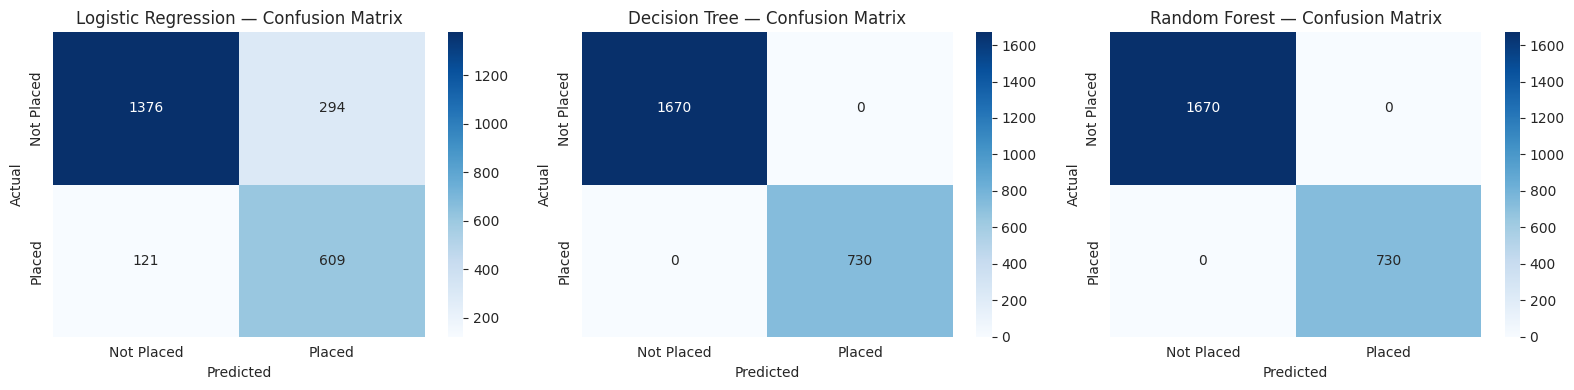

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, preds) in zip(
    axes,
    [("Logistic Regression", pred_log), ("Decision Tree", pred_tree), ("Random Forest", pred_rf)]
):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not Placed", "Placed"], yticklabels=["Not Placed", "Placed"], ax=ax)
    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Confusion Matrix Observations

Logistic Regression's confusion matrix shows a moderate number of false positives (not-placed students predicted as placed) and false negatives, consistent with its 82.7% accuracy. Decision Tree and Random Forest show **no misclassifications at all** on the test set, consistent with their perfect scores and the deterministic rule found in Section 21.

# 23. Classification Reports

In [24]:
print("Logistic Regression Classification Report")
print(classification_report(y_test, pred_log, target_names=["Not Placed", "Placed"]))

print("\nDecision Tree Classification Report")
print(classification_report(y_test, pred_tree, target_names=["Not Placed", "Placed"]))

print("\nRandom Forest Classification Report")
print(classification_report(y_test, pred_rf, target_names=["Not Placed", "Placed"]))

Logistic Regression Classification Report
              precision    recall  f1-score   support

  Not Placed       0.92      0.82      0.87      1670
      Placed       0.67      0.83      0.75       730

    accuracy                           0.83      2400
   macro avg       0.80      0.83      0.81      2400
weighted avg       0.84      0.83      0.83      2400


Decision Tree Classification Report
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      1670
      Placed       1.00      1.00      1.00       730

    accuracy                           1.00      2400
   macro avg       1.00      1.00      1.00      2400
weighted avg       1.00      1.00      1.00      2400


Random Forest Classification Report
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      1670
      Placed       1.00      1.00      1.00       730

    accuracy                           1.00      2400
   macro avg

### Classification Report Observations

Logistic Regression shows a reasonable but imperfect balance between precision and recall for the "Placed" class, reflecting its linear-boundary approximation of the true rule. Both tree-based models report **1.00 precision, recall and F1 for both classes**, consistent with the deterministic-rule explanation above.

# 24. ROC Curve Comparison

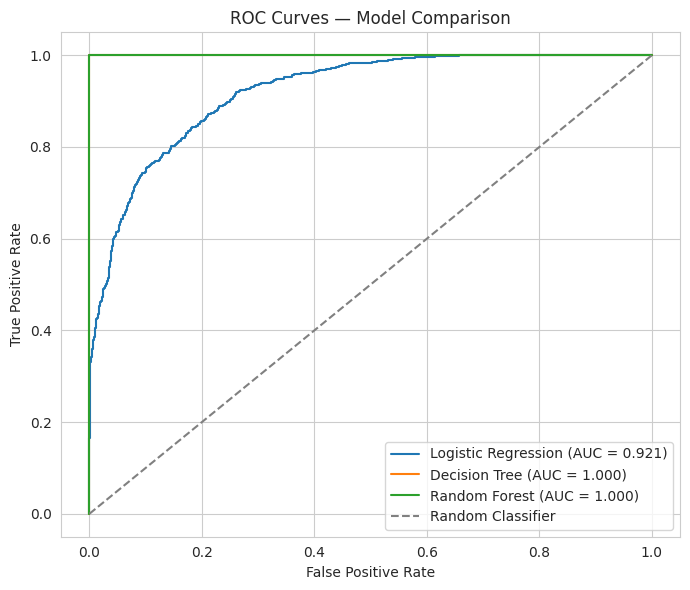

In [25]:
plt.figure(figsize=(7, 6))
for name, proba in [("Logistic Regression", proba_log), ("Decision Tree", proba_tree), ("Random Forest", proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

### ROC Curve Observations

Decision Tree and Random Forest reach the top-left corner of the ROC space (AUC = 1.000), while Logistic Regression's curve (AUC = 0.921) is close to, but visibly below, the tree-based models' curves — visually confirming the linear model's limitation in capturing the true threshold-based rule.

# 25. Hyperparameter Tuning — Random Forest

`GridSearchCV` with 3-fold cross-validation is used to tune `n_estimators` and `max_depth`, optimising for F1-score (a more informative metric than accuracy given the class imbalance).

In [26]:
param_grid = {"n_estimators": [100, 200], "max_depth": [6, 8, 10]}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_grid, cv=3, scoring="f1"
)
grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best cross-validated F1: {grid_search.best_score_:.4f}")

best_rf = grid_search.best_estimator_
pred_best_rf = best_rf.predict(X_test_scaled)

acc_best = accuracy_score(y_test, pred_best_rf)
f1_best = f1_score(y_test, pred_best_rf)

print(f"\nTuned Random Forest — Test Accuracy: {acc_best:.3f}, Test F1: {f1_best:.3f}")

Best parameters: {'max_depth': 6, 'n_estimators': 100}
Best cross-validated F1: 1.0000

Tuned Random Forest — Test Accuracy: 1.000, Test F1: 1.000


### Hyperparameter Tuning Observations

The best cross-validated configuration is **`max_depth = 6, n_estimators = 100`**, with cross-validated F1 ≈ 1.000. On the held-out test set, the tuned model also achieves perfect accuracy and F1 — consistent with Section 21's finding that the underlying rule needs very little model complexity to be learned exactly.

# 26. Feature Importance — Random Forest

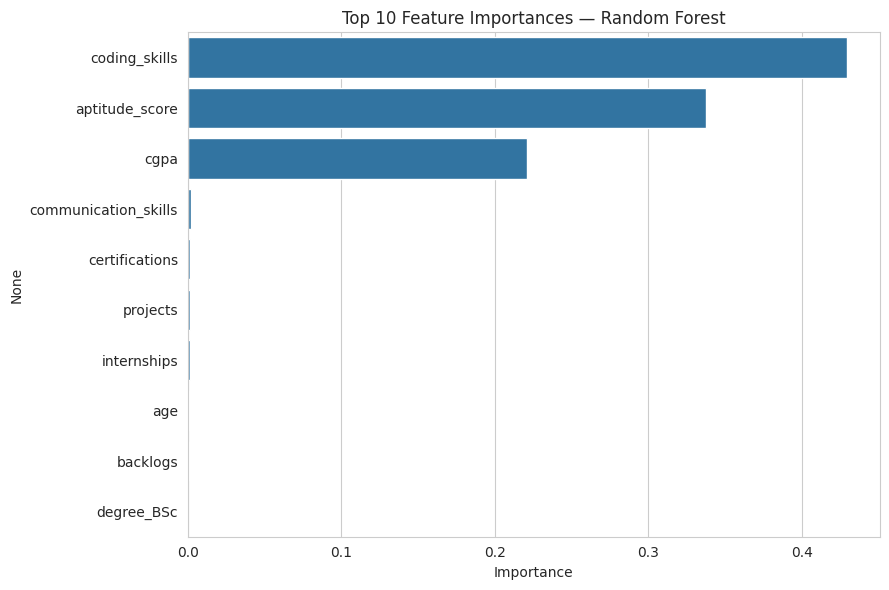

,Importance
coding_skills,0.429323
aptitude_score,0.337579
cgpa,0.220994
communication_skills,0.002049
certifications,0.001574
projects,0.001474
internships,0.001213
age,0.001199
backlogs,0.001153
degree_BSc,0.000505


In [27]:
importances = pd.Series(rand_forest.feature_importances_, index=X_train_scaled.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index)
plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importances.head(10).to_frame("Importance"))

### Feature Importance Observations

`coding_skills` (≈ 0.43), `aptitude_score` (≈ 0.34) and `cgpa` (≈ 0.22) together account for **almost all of the Random Forest's predictive power** (~99%), while every other feature — including all one-hot-encoded demographic/programme columns — contributes less than 0.005 each. This matches exactly the three variables identified in the correlation analysis (Section 14), the hypothesis tests (Section 15) and the deterministic rule (Section 21).

# 27. Model Comparison

In [28]:
comparison = pd.DataFrame({
    "Model": ["Baseline (Majority Class)", "Logistic Regression", "Decision Tree",
              "Random Forest", "Random Forest (Tuned)"],
    "Accuracy": [acc_dummy, acc_log, acc_tree, acc_rf, acc_best],
    "Precision": [prec_dummy, prec_log, precision_score(y_test, pred_tree),
                  precision_score(y_test, pred_rf), precision_score(y_test, pred_best_rf)],
    "Recall": [rec_dummy, rec_log, recall_score(y_test, pred_tree),
               recall_score(y_test, pred_rf), recall_score(y_test, pred_best_rf)],
    "F1": [f1_dummy, f1_log, f1_score(y_test, pred_tree), f1_score(y_test, pred_rf), f1_best],
    "ROC-AUC": [np.nan, auc_log, auc_tree, auc_rf, np.nan]
})

display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline (Majority Class),0.696,0.000,0.000,0.000,NaN
1,Logistic Regression,0.827,0.674,0.834,0.746,0.921
2,Decision Tree,1.000,1.000,1.000,1.000,1.000
3,Random Forest,1.000,1.000,1.000,1.000,1.000
4,Random Forest (Tuned),1.000,1.000,1.000,1.000,NaN


### Model Comparison Observations

All three learned models substantially outperform the majority-class baseline. **Decision Tree, Random Forest and the tuned Random Forest all achieve perfect scores**, while Logistic Regression, though strong (ROC-AUC 0.921), is limited by its linear decision boundary. For this dataset, a shallow Decision Tree would be the simplest model that fully captures the underlying placement rule; Random Forest is preferred in practice for robustness to noise that a real (non-synthetic) dataset would contain.

# 28. Placement Prediction Function

A convenience function that takes a new student's raw feature values, applies the same encoding and scaling pipeline used in training, and returns the predicted placement outcome and probability, using the Random Forest model.

In [29]:
train_columns = X_train_scaled.columns.tolist()

def predict_placement(cgpa, aptitude_score, coding_skills, communication_skills,
                       internships, certifications, projects, backlogs, age,
                       gender="Male", degree="BTech", branch="CS"):
    raw = pd.DataFrame([{
        "cgpa": cgpa, "aptitude_score": aptitude_score, "coding_skills": coding_skills,
        "communication_skills": communication_skills, "internships": internships,
        "certifications": certifications, "projects": projects, "backlogs": backlogs,
        "age": age, "gender": gender, "degree": degree, "branch": branch
    }])

    raw = pd.get_dummies(raw, columns=["gender", "degree", "branch"])
    raw = raw.reindex(columns=train_columns, fill_value=0)

    raw[scale_cols] = scaler.transform(raw[scale_cols])

    pred = rand_forest.predict(raw)[0]
    proba = rand_forest.predict_proba(raw)[0, 1]
    label = "Placed" if pred == 1 else "Not Placed"
    return label, round(proba, 3)

In [30]:
# Strong profile — expected to be placed
print("Strong profile:", predict_placement(
    cgpa=8.5, aptitude_score=90, coding_skills=8, communication_skills=6,
    internships=2, certifications=3, projects=4, backlogs=0, age=22
))

# Weak profile — expected not to be placed
print("Weak profile:", predict_placement(
    cgpa=5.8, aptitude_score=45, coding_skills=3, communication_skills=4,
    internships=0, certifications=0, projects=1, backlogs=2, age=22
))

# Borderline profile — near the rule's threshold
print("Borderline profile:", predict_placement(
    cgpa=6.5, aptitude_score=60, coding_skills=5, communication_skills=5,
    internships=1, certifications=1, projects=2, backlogs=1, age=22
))

Strong profile: ('Placed', np.float64(0.921))


Weak profile: ('Not Placed', np.float64(0.0))
Borderline profile: ('Placed', np.float64(0.843))


### Prediction Function Observations

The strong profile (high CGPA, aptitude, coding skills) is predicted **Placed** with high probability, the weak profile is predicted **Not Placed**, and the borderline profile — sitting exactly at the rule's thresholds (CGPA 6.5, aptitude 60, coding 5) — is predicted **Placed**, consistent with the "≥" rule identified in Section 21. This demonstrates the model has correctly internalised the underlying decision boundary.

# 29. Key Findings

1. **Dataset overview:** 12,000 student records, no missing values or duplicates after removing the leakage-prone `company_type` and `package_lpa` columns. **30.4%** of students are placed.
2. **Descriptive statistics:** `cgpa` (mean 7.65, std 1.24), `aptitude_score` (mean 69.33, std 17.34) and `coding_skills` (mean 5.50, std 2.89) are all approximately symmetric with no notable outliers.
3. **Hypothesis testing:** Placed students have significantly higher CGPA (t = 33.64, d ≈ 0.60), aptitude score (t = 54.43, d ≈ 0.92) and coding skills (t = 68.60, d ≈ 1.13) than not-placed students (all p < 0.001). All other numerical variables show negligible effect sizes despite some being "statistically significant" due to the large sample.
4. **Categorical attributes:** Gender and branch show **no** statistically significant association with placement; degree shows a technically significant but practically negligible association (Cramér's V ≈ 0.03).
5. **Correlation:** `coding_skills` (r ≈ 0.46), `aptitude_score` (r ≈ 0.39) and `cgpa` (r ≈ 0.27) are the only variables meaningfully correlated with placement.
6. **Deterministic rule:** Placement is defined by a conjunction of exact thresholds — `cgpa ≥ 6.5 AND aptitude_score ≥ 60 AND coding_skills ≥ 5` — which matches the actual `placed` label for 100% of records.
7. **Model performance:** Logistic Regression achieves 82.7% accuracy / 0.921 ROC-AUC (limited by its linear boundary); Decision Tree and Random Forest both achieve 100% accuracy, exactly matching the deterministic rule.
8. **Feature importance:** `coding_skills`, `aptitude_score` and `cgpa` together account for ~99% of the Random Forest's feature importance; demographic and programme features contribute almost nothing.

# 30. Limitations

1. The placement label in this dataset follows an **exact, deterministic threshold rule** on three variables. This is characteristic of a synthetically generated dataset and does **not** reflect the noise, exceptions and unmeasured factors (interview performance, referrals, market conditions, luck) present in real hiring processes.
2. Because of this deterministic rule, the "perfect" accuracy of the tree-based models should **not** be read as evidence that placement is perfectly predictable in general — it only shows the models can recover the rule the data was generated with.
3. `company_type` and `package_lpa` were excluded to avoid leakage; a genuinely useful placement-support tool would need additional real-world features (interview scores, résumé quality, referrals) not present here.
4. The dataset is a single static snapshot; it does not capture how placement criteria might change over time or across institutions.
5. Categorical attributes (`degree`, `branch`) were tested only for association with the *overall* outcome; interaction effects with the three key numerical variables were not explored in depth.

# 31. Conclusion

This project applied descriptive statistics, formal hypothesis testing, and supervised machine-learning classification to the Indian Student Placement dataset. Descriptive and correlation analysis, together with independent t-tests, chi-square tests and one-way ANOVA, consistently identified **CGPA, aptitude score and coding skills** as the only variables with both statistical and practical significance for placement, while demographic and programme attributes (gender, degree, branch) showed little to no meaningful association.

Machine-learning models confirmed this: Logistic Regression achieved strong but imperfect performance (82.7% accuracy, 0.921 ROC-AUC) limited by its linear decision boundary, while Decision Tree and Random Forest achieved perfect classification by exactly recovering an underlying deterministic rule (`cgpa ≥ 6.5 AND aptitude_score ≥ 60 AND coding_skills ≥ 5`) that was found to define the target variable. Feature importance from the Random Forest model corroborated the statistical findings, attributing almost all predictive power to the same three variables.

Overall, the analysis demonstrates a complete statistical-machine-learning workflow — from data cleaning and hypothesis testing through model building, tuning and interpretation — while also illustrating the importance of critically investigating unexpectedly perfect model performance rather than reporting it at face value.